
# COU 07506 Digital Signal Processing — Week 01: Setting Up the DSP Laboratory

Name: Debora Bryson Lema 
Registration No.: 240242455798 
Class: BEng24CO-4 
Group: GROUP 1  
Date: 24 November 2026  


## Pre-lab

Question: List three devices you used today that contain Digital Signal Processing (DSP), and name one signal processed by each.

1. Smartphone: Processes audio signals during voice calls and recording.
2. Laptop: Processes audio signals through its microphone and sound output system.
3. Wireless earbuds: Process audio signals for noise cancellation and sound enhancement.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Digital Signal Processing environment ready.")

Digital Signal Processing environment ready.


## Task 1.1 — Generation and Plotting of Elementary Discrete-Time Signals

Objective: To generate and visualize the unit impulse, unit step, unit ramp and real exponential signals using Python.

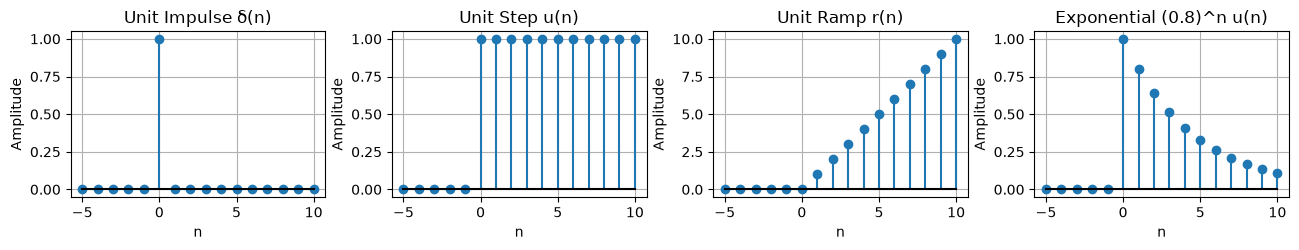

In [2]:
# Required imports
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

# Task 1.1: Generate basic discrete-time signals
n = np.arange(-5, 11)

delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = 0.8**n * step

# Plot the four signals
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["Unit Impulse δ(n)", "Unit Step u(n)",
     "Unit Ramp r(n)", "Exponential (0.8)^n u(n)"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()

## Task 1.2: Exploring Exponential and Sinusoidal Signals

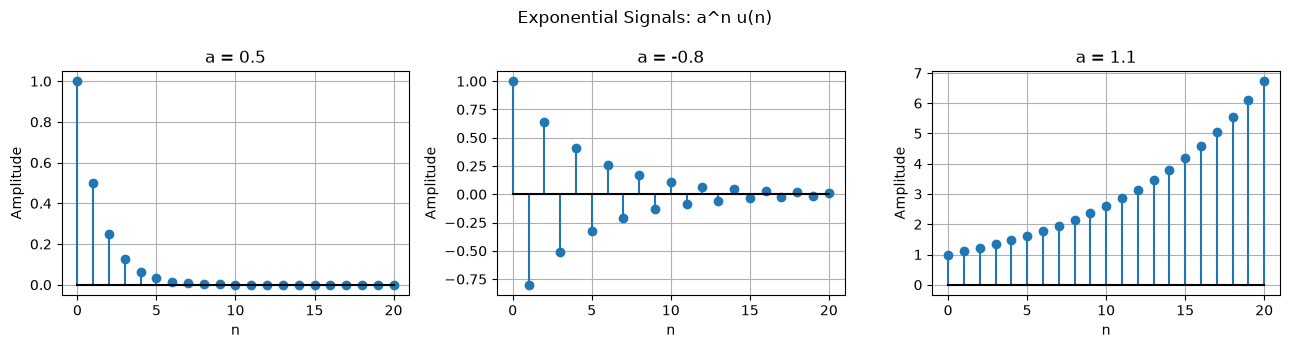

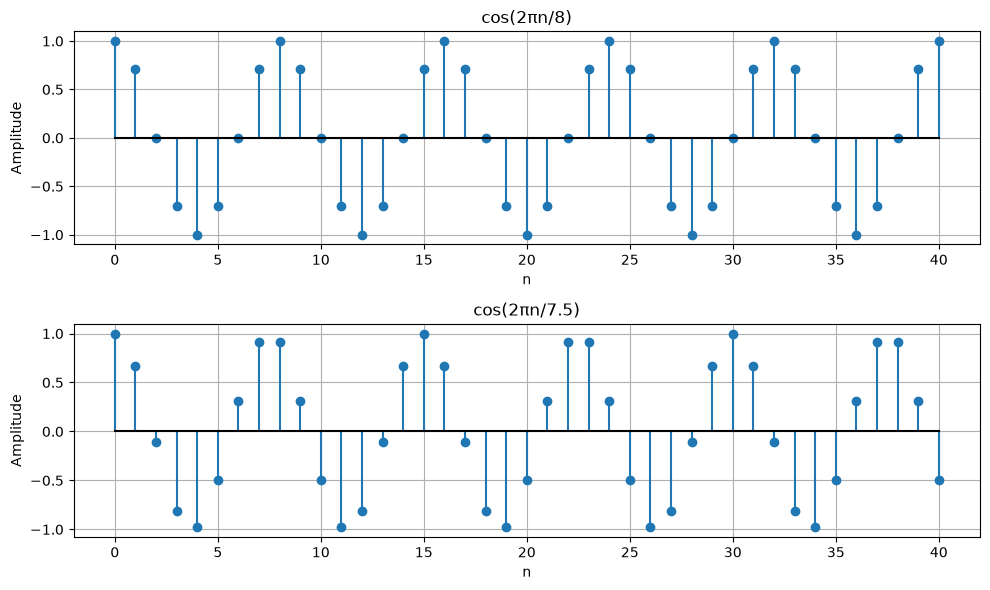

In [1]:
# Required imports
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

# Task 1.2(a): Plot exponential signals
n = np.arange(0, 21)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

for ax, a in zip(axes, a_values):
    x = (a ** n)
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.suptitle("Exponential Signals: a^n u(n)")
plt.tight_layout()
plt.show()


# Task 1.2(b): Compare two cosine signals
n = np.arange(0, 41)

x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].stem(n, x1, basefmt="k-")
axes[0].set_title("cos(2πn/8)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].stem(n, x2, basefmt="k-")
axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Observations

1. For a = 0.5, the exponential signal decreases towards zero as n increases.
2. For a = -0.8, the signal alternates between positive and negative values while its magnitude decreases.
3. For a = 1.1, the exponential signal grows as n increases.
4. The signal cos(2πn/8) is periodic because its period is 8 samples, an integer.
5. The signal cos(2πn/7.5) is not periodic in discrete time because its period is not an integer.

## Task 1.3: Recording and Analysing an Audio Signal

In [1]:
# Required imports
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

# Task 1.3: Generate a test audio signal
fs = 16000
t = np.arange(0, 2, 1/fs)

x = 0.5 * np.sin(2 * np.pi * 440 * t) * np.exp(-t)

# Convert to 16-bit PCM format
audio = np.int16(x * 32767)

# Save as a WAV file
wavfile.write("test_audio.wav", fs, audio)

print("Audio file created successfully.")
print("Sampling rate:", fs, "Hz")
print("Duration:", len(x) / fs, "seconds")
print("Number of samples:", len(x))

Audio file created successfully.
Sampling rate: 16000 Hz
Duration: 2.0 seconds
Number of samples: 32000


Sampling rate: 16000 Hz
Duration: 2.0 seconds
Number of samples: 32000


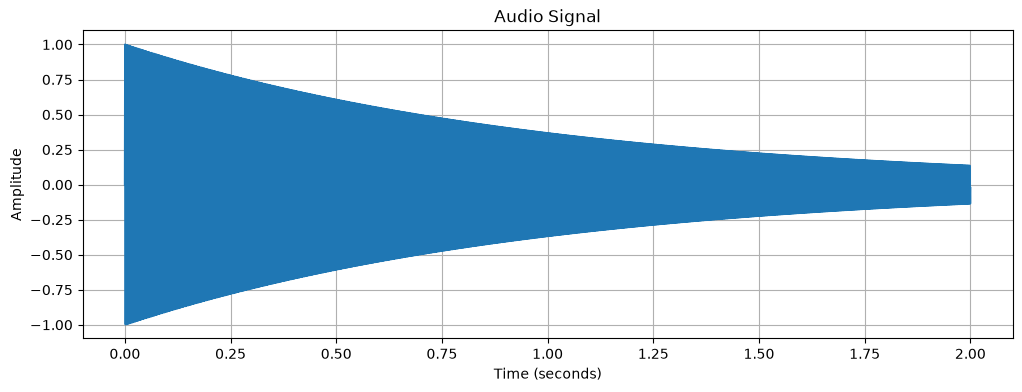

In [1]:
# Required imports
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

# Load audio recording
fs, x = wavfile.read("test_audio.wav")

# Convert stereo to mono if necessary
if x.ndim == 2:
    x = x.mean(axis=1)

# Normalize audio
x = x.astype(float)
x = x / np.max(np.abs(x))

# Create time axis
t = np.arange(len(x)) / fs

# Display audio information
print("Sampling rate:", fs, "Hz")
print("Duration:", len(x) / fs, "seconds")
print("Number of samples:", len(x))

# Plot audio signal
plt.figure(figsize=(12, 4))
plt.plot(t, x)
plt.title("Audio Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

### Observations

1. The audio signal was successfully loaded from the WAV file.
2. The sampling rate was 16,000 Hz.
3. The duration of the audio signal was 2 seconds.
4. The signal contains 32,000 samples.
5. The waveform gradually decreases in amplitude because an exponential decay factor was applied to the sinusoidal signal.

## Analysis Questions

### Question 1: Sampling Rate and Storage

The sampling rate of the audio signal is 16,000 Hz. This means that 16,000 samples are taken every second.

To calculate the number of samples required to store one minute of mono audio:

Number of samples = Sampling rate × Duration

= 16,000 × 60

= 960,000 samples

Therefore, one minute of mono audio sampled at 16,000 Hz requires 960,000 numerical samples.

### Question 2: Discrete-Time Signals and Stem Plots

A stem plot is more appropriate for representing a discrete-time signal because discrete-time signals consist of individual samples defined only at specific integer time indices.

Each vertical stem represents the amplitude of a sample at a particular index. Unlike a continuous line plot, a stem plot does not suggest that the signal has values between the sampling points.

Therefore, stem plots provide a more accurate visual representation of the discrete nature of digital signals.

### Question 3: BIBO Stability

The system would violate the Bounded-Input Bounded-Output (BIBO) stability property.

For a discrete-time linear time-invariant (LTI) system to be BIBO stable, its impulse response must be absolutely summable:

Σ |h(n)| < ∞

When a = 1.1, the exponential signal grows continuously as n increases. Therefore, the sum of its absolute values does not converge to a finite value.

Consequently, the system would be BIBO unstable.

## AI-Use Statement

AI tools used: ChatGPT.

Used for: Understanding laboratory instructions, explaining DSP concepts, and receiving guidance on Python code implementation.

How I verified the output: I executed the code cells in JupyterLab and checked that the generated plots, audio information, and calculations were consistent with the expected results.

I confirm that I understand and can explain all submitted code.